In [1]:
from pathlib import Path
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Project root: notebook is inside the notebooks folder
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
MODELS_DIR = PROJECT_ROOT / "src" / "models"

for folder in [PROCESSED_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data folder exists:", RAW_DIR.exists())

Project root: /home/sharath/projects/uber-eats-intelligence
Raw data folder exists: True


## Load and inspect the data

In [2]:
customers = pd.read_csv(RAW_DIR / "customers.csv")
restaurants = pd.read_csv(RAW_DIR / "restaurants.csv")
orders = pd.read_csv(RAW_DIR / "orders.csv")
deliveries = pd.read_csv(RAW_DIR / "deliveries.csv")
reviews = pd.read_csv(RAW_DIR / "reviews.csv")

datasets = {
    "Customers": customers,
    "Restaurants": restaurants,
    "Orders": orders,
    "Deliveries": deliveries,
    "Reviews": reviews
}

for name, df in datasets.items():
    print(f"\n{name}: {df.shape}")
    print(df.columns.tolist())


Customers: (500, 6)
['customer_id', 'age', 'gender', 'city', 'membership_type', 'signup_date']

Restaurants: (50, 6)
['restaurant_id', 'city', 'cuisine', 'restaurant_rating', 'average_prep_time_minutes', 'price_level']

Orders: (5000, 14)
['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'item_count', 'order_status', 'order_amount', 'discount', 'delivery_fee', 'tax', 'total_amount', 'hour', 'day_of_week', 'is_weekend']

Deliveries: (4410, 7)
['order_id', 'driver_id', 'distance_km', 'weather', 'traffic', 'prep_time_minutes', 'delivery_time_minutes']

Reviews: (1984, 6)
['review_id', 'order_id', 'customer_id', 'rating', 'review_text', 'review_timestamp']


In [3]:
for name, df in datasets.items():
    print(f"\n{'=' * 45}")
    print(name)
    print("Rows:", len(df))
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values by column:")
    print(df.isnull().sum())


Customers
Rows: 500
Duplicate rows: 0
Missing values by column:
customer_id        0
age                0
gender             0
city               0
membership_type    0
signup_date        0
dtype: int64

Restaurants
Rows: 50
Duplicate rows: 0
Missing values by column:
restaurant_id                0
city                         0
cuisine                      0
restaurant_rating            0
average_prep_time_minutes    0
price_level                  0
dtype: int64

Orders
Rows: 5000
Duplicate rows: 0
Missing values by column:
order_id           0
customer_id        0
restaurant_id      0
order_timestamp    0
item_count         0
order_status       0
order_amount       0
discount           0
delivery_fee       0
tax                0
total_amount       0
hour               0
day_of_week        0
is_weekend         0
dtype: int64

Deliveries
Rows: 4410
Duplicate rows: 0
Missing values by column:
order_id                 0
driver_id                0
distance_km              0
weather      

In [4]:
# Convert timestamps to datetime
for df, column in [
    (orders, "order_timestamp"),
    (reviews, "review_timestamp")
]:
    if column in df.columns:
        df[column] = pd.to_datetime(df[column], errors="coerce")

# Inspect actual order statuses before calculating cancellations
print("Order statuses:")
print(orders["order_status"].value_counts(dropna=False))

print("\nOrder date range:")
print(orders["order_timestamp"].min(), "to", orders["order_timestamp"].max())

Order statuses:
order_status
Delivered    4410
Cancelled     445
Failed        145
Name: count, dtype: int64

Order date range:
2026-04-01 00:37:00 to 2026-09-30 23:43:00


## Part 1 – Feature Engineering

**Customers** (delivered orders only): total orders, average order value, total spending, ordering frequency (orders per active month), average rating given, weekend orders, late-night orders (10 PM – 5 AM).
Two extra *share* features are added (`weekend_share`, `late_night_share`) so that "weekend / late-night behaviour" is measured independently of how much a customer orders.

**Restaurants:** total orders, revenue, average rating, average preparation time, cancellation rate, average delivery time.

Identifiers (`customer_id`, `restaurant_id`) are kept in the dataframes for joining/reporting but are **never** passed to the models.

In [5]:
# Treat completed/delivered orders as successful orders.
successful_statuses = ["delivered", "completed"]

completed_orders = orders[
    orders["order_status"].astype(str).str.lower().isin(successful_statuses)
].copy()

# Extract date-related features
completed_orders["order_month"] = completed_orders["order_timestamp"].dt.to_period("M")
completed_orders["order_hour"] = completed_orders["order_timestamp"].dt.hour

# Weekend orders: use existing field if available, otherwise calculate
if "is_weekend" in completed_orders.columns:
    completed_orders["weekend_flag"] = (
        completed_orders["is_weekend"].astype(str).str.lower()
        .isin(["true", "1", "yes"])
    ).astype(int)
else:
    completed_orders["weekend_flag"] = (
        completed_orders["order_timestamp"].dt.dayofweek >= 5
    ).astype(int)

# Late-night orders: 10 PM to before 5 AM
completed_orders["late_night_flag"] = (
    (completed_orders["order_hour"] >= 22) |
    (completed_orders["order_hour"] < 5)
).astype(int)

customer_features = completed_orders.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    average_order_value=("total_amount", "mean"),
    total_spending=("total_amount", "sum"),
    weekend_orders=("weekend_flag", "sum"),
    late_night_orders=("late_night_flag", "sum"),
    first_order_date=("order_timestamp", "min"),
    last_order_date=("order_timestamp", "max"),
    active_months=("order_month", "nunique")
).reset_index()

# Ordering frequency: orders per month with activity
customer_features["ordering_frequency"] = (
    customer_features["total_orders"] /
    customer_features["active_months"].replace(0, np.nan)
)

# NEW: behaviour shares, independent of order volume
customer_features["weekend_share"] = (
    customer_features["weekend_orders"] / customer_features["total_orders"]
)
customer_features["late_night_share"] = (
    customer_features["late_night_orders"] / customer_features["total_orders"]
)

# Average rating given by each customer (customers with no review get the overall mean)
customer_ratings = reviews.groupby("customer_id")["rating"].mean()
customer_features["average_rating_given"] = (
    customer_features["customer_id"].map(customer_ratings)
)
print("Customers with no review (imputed):",
      customer_features["average_rating_given"].isna().sum())
customer_features["average_rating_given"] = (
    customer_features["average_rating_given"].fillna(reviews["rating"].mean())
)

customer_features.to_csv(PROCESSED_DIR / "customer_features.csv", index=False)

print("Customer feature table:", customer_features.shape)
customer_features.head()

Customers with no review (imputed): 7
Customer feature table: (500, 13)


,customer_id,total_orders,average_order_value,total_spending,weekend_orders,late_night_orders,first_order_date,last_order_date,active_months,ordering_frequency,weekend_share,late_night_share,average_rating_given
0,C0001,8,1044.958750,8359.67,3,2,2026-04-05 11:55:00,2026-08-28 21:18:00,4,2.0,0.375000,0.250000,3.000000
1,C0002,7,1057.384286,7401.69,3,3,2026-04-18 02:24:00,2026-09-27 00:17:00,5,1.4,0.428571,0.428571,3.500000
2,C0003,10,787.707000,7877.07,2,2,2026-04-14 23:04:00,2026-09-24 13:45:00,4,2.5,0.200000,0.200000,4.428571
3,C0004,8,952.198750,7617.59,1,2,2026-04-14 09:28:00,2026-09-23 05:58:00,4,2.0,0.125000,0.250000,3.333333
4,C0005,10,884.784000,8847.84,4,3,2026-04-11 19:00:00,2026-09-03 22:02:00,5,2.0,0.400000,0.300000,3.800000


In [6]:
# All orders (incl. cancelled/failed) are needed for volume and cancellation rate.
status = orders["order_status"].astype(str).str.lower()
orders["cancelled_flag"] = status.isin({"cancelled", "canceled"}).astype(int)
orders["failed_flag"] = (status == "failed").astype(int)

restaurant_features = orders.groupby("restaurant_id").agg(
    total_orders=("order_id", "nunique"),            # orders received
    cancellation_rate=("cancelled_flag", "mean"),    # cancelled / all orders
    failed_rate=("failed_flag", "mean")              # kept for reference, not a model input
).reset_index()

# Revenue: only delivered orders actually generate revenue
revenue = completed_orders.groupby("restaurant_id")["total_amount"].sum().rename("revenue")
restaurant_features = restaurant_features.merge(revenue, on="restaurant_id", how="left")
restaurant_features["revenue"] = restaurant_features["revenue"].fillna(0)

# FIX: use the real column names from restaurants.csv
restaurant_info = restaurants[[
    "restaurant_id", "restaurant_rating", "average_prep_time_minutes",
    "cuisine", "city", "price_level"
]].rename(columns={
    "restaurant_rating": "average_rating",
    "average_prep_time_minutes": "average_prep_time"
})
restaurant_features = restaurant_features.merge(
    restaurant_info, on="restaurant_id", how="left"
)

# Average delivery time from delivered orders
delivery_times = deliveries.merge(
    completed_orders[["order_id", "restaurant_id"]], on="order_id", how="inner"
)
restaurant_features["average_delivery_time"] = restaurant_features["restaurant_id"].map(
    delivery_times.groupby("restaurant_id")["delivery_time_minutes"].mean()
)

# Safety check: nothing should be missing in the model inputs any more
model_inputs = ["total_orders", "revenue", "average_rating",
                "average_prep_time", "cancellation_rate", "average_delivery_time"]
print("Missing values in restaurant model inputs:")
print(restaurant_features[model_inputs].isna().sum())

restaurant_features.to_csv(PROCESSED_DIR / "restaurant_features.csv", index=False)
restaurant_features.head()

Missing values in restaurant model inputs:
total_orders             0
revenue                  0
average_rating           0
average_prep_time        0
cancellation_rate        0
average_delivery_time    0
dtype: int64


,restaurant_id,total_orders,cancellation_rate,failed_rate,revenue,average_rating,average_prep_time,cuisine,city,price_level,average_delivery_time
0,R001,110,0.118182,0.036364,78081.67,5.0,37,Desserts,Mumbai,Premium,70.806452
1,R002,98,0.091837,0.010204,64096.00,4.3,10,Desserts,Pune,Moderate,45.795455
2,R003,106,0.075472,0.028302,77188.25,4.2,17,Healthy,Delhi,Premium,52.652632
3,R004,100,0.080000,0.040000,71238.36,3.2,32,Biryani,Delhi,Moderate,68.409091
4,R005,101,0.079208,0.049505,73006.49,4.7,32,Healthy,Mumbai,Premium,67.693182


### Feature selection – check for redundant features
Distance-based algorithms treat every column as an independent dimension. Highly correlated features therefore count the same information twice.

Customer model features: ['total_orders', 'average_order_value', 'average_rating_given', 'weekend_share', 'late_night_share']
Restaurant model features: ['total_orders', 'revenue', 'average_rating', 'average_prep_time', 'cancellation_rate', 'average_delivery_time']

Identifiers excluded from models: True


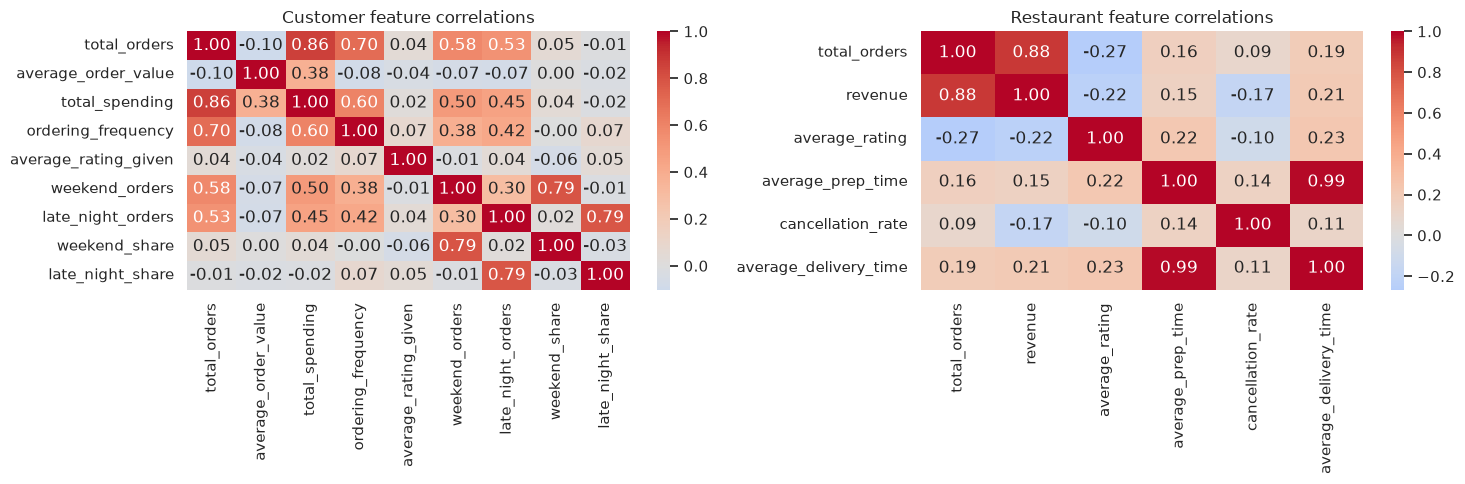

In [7]:
# All 7 required customer features were engineered above. For *modelling* we keep one
# representative per correlated group:
#   total_spending  ≈ total_orders × average_order_value  (corr with total_orders ≈ 0.86)
#   ordering_frequency is derived from total_orders
#   weekend/late-night COUNTS grow with total_orders -> use the SHARES instead
customer_feature_cols = [
    "total_orders",
    "average_order_value",
    "average_rating_given",
    "weekend_share",
    "late_night_share"
]

restaurant_feature_cols = [
    "total_orders",
    "revenue",
    "average_rating",
    "average_prep_time",
    "cancellation_rate",
    "average_delivery_time"
]

print("Customer model features:", customer_feature_cols)
print("Restaurant model features:", restaurant_feature_cols)
print("\nIdentifiers excluded from models:",
      "customer_id" not in customer_feature_cols and
      "restaurant_id" not in restaurant_feature_cols)

# Show correlations among all engineered customer features and the restaurant features
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(
    customer_features[["total_orders", "average_order_value", "total_spending",
                       "ordering_frequency", "average_rating_given",
                       "weekend_orders", "late_night_orders",
                       "weekend_share", "late_night_share"]].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0]
)
axes[0].set_title("Customer feature correlations")
sns.heatmap(
    restaurant_features[restaurant_feature_cols].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1]
)
axes[1].set_title("Restaurant feature correlations")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

## Part 2 – Missing values and scaling (StandardScaler)

Missing numeric values are filled with the **median**, and every feature is standardised to mean 0 and standard deviation 1.

**Why scaling matters for K-Means and DBSCAN:** both algorithms group points by Euclidean distance. Features measured on large scales (e.g. `revenue` in tens of thousands, `total_orders` in the hundreds) would dominate the distance, while small-scale features (e.g. `cancellation_rate` between 0 and 0.15, ratings between 1 and 5) would barely influence it. The clusters would then mostly reflect the largest-scale column instead of the real behaviour. `StandardScaler` puts all features on the same scale so each contributes comparably. Scaling is also needed before PCA, which is variance-based.

In [8]:
def prepare_features(df, feature_cols):
    X = df[feature_cols].copy()

    for col in X.columns:
        X[col] = pd.to_numeric(X[col], errors="coerce")

    X = X.replace([np.inf, -np.inf], np.nan)

    # Fail loudly instead of silently dropping a feature (this hid the earlier bug)
    empty_cols = X.columns[X.isna().all()].tolist()
    if empty_cols:
        raise ValueError(f"These features contain no usable values: {empty_cols}")

    imputer = SimpleImputer(strategy="median")
    X_imputed = pd.DataFrame(
        imputer.fit_transform(X), columns=X.columns, index=X.index
    )

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_imputed)

    return X_imputed, X_scaled, imputer, scaler


customer_X, customer_scaled, customer_imputer, customer_scaler = (
    prepare_features(customer_features, customer_feature_cols)
)

restaurant_X, restaurant_scaled, restaurant_imputer, restaurant_scaler = (
    prepare_features(restaurant_features, restaurant_feature_cols)
)

print("Customer model matrix:", customer_scaled.shape)
print("Restaurant model matrix:", restaurant_scaled.shape)

print("\nScaled customer feature mean / std:")
print(pd.DataFrame({
    "mean": customer_scaled.mean(axis=0),
    "std": customer_scaled.std(axis=0)
}, index=customer_X.columns).round(2))

Customer model matrix: (500, 5)
Restaurant model matrix: (50, 6)

Scaled customer feature mean / std:
                      mean  std
total_orders          -0.0  1.0
average_order_value    0.0  1.0
average_rating_given   0.0  1.0
weekend_share          0.0  1.0
late_night_share      -0.0  1.0


## Part 3 – K-Means: choosing k with the Elbow method and Silhouette score

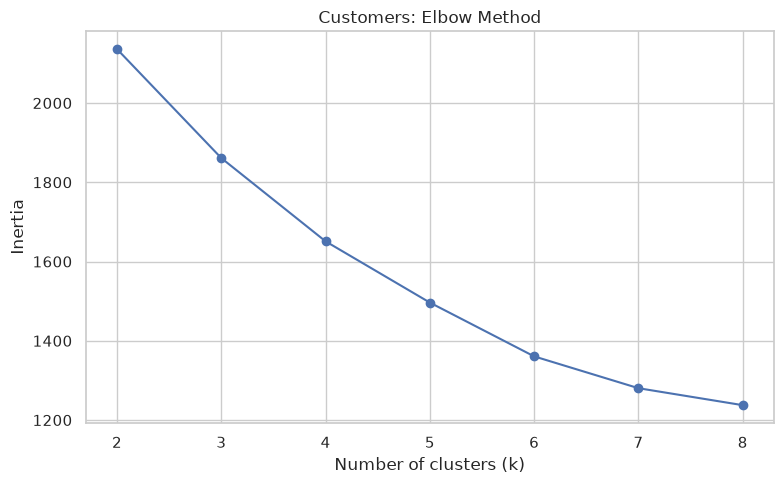

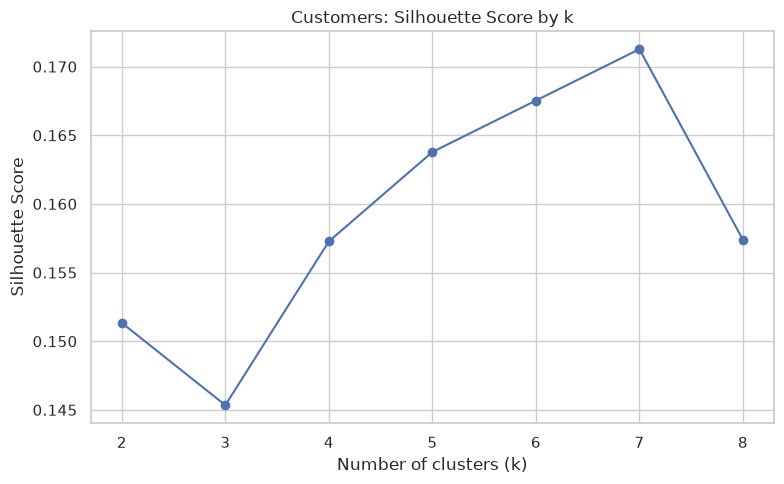

   k   inertia  silhouette_score
0  2  2135.955             0.151
1  3  1861.059             0.145
2  4  1650.959             0.157
3  5  1496.393             0.164
4  6  1360.691             0.168
5  7  1280.411             0.171
6  8  1237.590             0.157

Highest silhouette score at k = 7


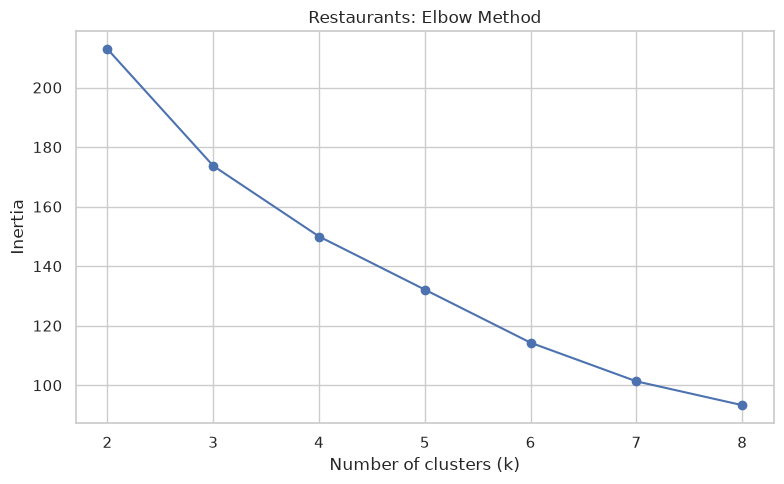

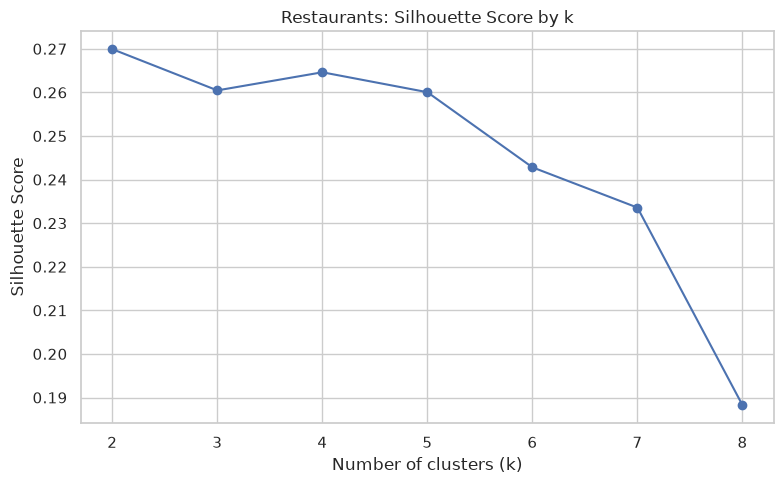

   k  inertia  silhouette_score
0  2  212.894             0.270
1  3  173.670             0.260
2  4  149.957             0.265
3  5  132.111             0.260
4  6  114.273             0.243
5  7  101.309             0.234
6  8   93.307             0.188

Highest silhouette score at k = 2


In [9]:
def evaluate_kmeans(X_scaled, prefix, max_k=8):
    if len(X_scaled) < 3:
        raise ValueError("At least 3 observations are required.")

    max_k = min(max_k, len(X_scaled) - 1)
    k_values = range(2, max_k + 1)

    results = []

    for k in k_values:
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = model.fit_predict(X_scaled)
        score = silhouette_score(X_scaled, labels)

        results.append({"k": k, "inertia": model.inertia_, "silhouette_score": score})

    scores_df = pd.DataFrame(results)

    # Elbow plot
    plt.figure(figsize=(8, 5))
    plt.plot(scores_df["k"], scores_df["inertia"], marker="o")
    plt.title(f"{prefix}: Elbow Method")
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Inertia")
    plt.xticks(list(k_values))
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{prefix.lower()}_elbow.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Silhouette plot
    plt.figure(figsize=(8, 5))
    plt.plot(scores_df["k"], scores_df["silhouette_score"], marker="o")
    plt.title(f"{prefix}: Silhouette Score by k")
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Silhouette Score")
    plt.xticks(list(k_values))
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{prefix.lower()}_silhouette.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(scores_df.round(3))

    best_k = int(scores_df.loc[scores_df["silhouette_score"].idxmax(), "k"])
    print(f"\nHighest silhouette score at k = {best_k}")

    return scores_df, best_k


customer_k_results, best_customer_k = evaluate_kmeans(customer_scaled, "Customers")
restaurant_k_results, best_restaurant_k = evaluate_kmeans(restaurant_scaled, "Restaurants")

In [10]:
# Choose k using BOTH the elbow and the silhouette score, plus business usefulness.
# See the markdown note below for the reasoning behind these two values.
CUSTOMER_K = 4
RESTAURANT_K = 3

customer_kmeans = KMeans(n_clusters=CUSTOMER_K, random_state=42, n_init=10)
restaurant_kmeans = KMeans(n_clusters=RESTAURANT_K, random_state=42, n_init=10)

customer_features["kmeans_cluster"] = customer_kmeans.fit_predict(customer_scaled)
restaurant_features["kmeans_cluster"] = restaurant_kmeans.fit_predict(restaurant_scaled)

customer_sil = silhouette_score(customer_scaled, customer_features["kmeans_cluster"])
restaurant_sil = silhouette_score(restaurant_scaled, restaurant_features["kmeans_cluster"])
print(f"Customer K-Means   (k={CUSTOMER_K}) silhouette score: {customer_sil:.3f}")
print(f"Restaurant K-Means (k={RESTAURANT_K}) silhouette score: {restaurant_sil:.3f}")

# Save fitted models and preprocessing objects
joblib.dump(
    {"model": customer_kmeans, "scaler": customer_scaler,
     "imputer": customer_imputer, "features": list(customer_X.columns)},
    MODELS_DIR / "customer_kmeans.joblib"
)
joblib.dump(
    {"model": restaurant_kmeans, "scaler": restaurant_scaler,
     "imputer": restaurant_imputer, "features": list(restaurant_X.columns)},
    MODELS_DIR / "restaurant_kmeans.joblib"
)

print("\nCustomer cluster counts:")
print(customer_features["kmeans_cluster"].value_counts().sort_index())
print("\nRestaurant cluster counts:")
print(restaurant_features["kmeans_cluster"].value_counts().sort_index())

Customer K-Means   (k=4) silhouette score: 0.157
Restaurant K-Means (k=3) silhouette score: 0.260

Customer cluster counts:
kmeans_cluster
0    156
1    119
2    113
3    112
Name: count, dtype: int64

Restaurant cluster counts:
kmeans_cluster
0    20
1    11
2    19
Name: count, dtype: int64


**Choosing k**

* **Customers – k = 4.** The silhouette scores are low and nearly flat for k = 3–8 (about 0.15–0.17) and the elbow curve bends gradually, so the data has no sharply separated groups. k = 4 is the smallest value that gives four clearly different and explainable behaviours (high-volume, weekend big-spenders, weekday regulars, late-night orders) without splitting into tiny clusters.
* **Restaurants – k = 3.** Silhouette is highest at k = 2 (0.27) but k = 3 is almost identical (0.26) and the elbow bends at 3. k = 3 separates fast-prep, slow-prep/high-demand and top-rated restaurants, which a two-way split cannot.

A silhouette score below ~0.25 means weak cluster structure; read the segments as *tendencies* rather than hard boundaries.

## Part 4 – DBSCAN: dense groups, outliers and noise

DBSCAN needs `eps` (neighbourhood radius) and `min_samples`. Instead of guessing, `eps` is chosen from the **k-distance plot** and a small grid search. Points labelled **-1** are *noise / outliers*.

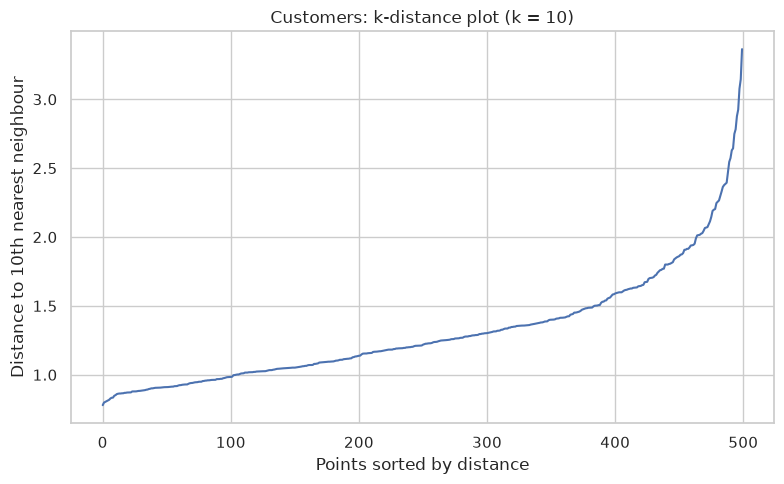


Customers DBSCAN grid (min_samples=10):
 eps  clusters  noise_points  noise_pct  silhouette_excl_noise
 0.8         1           483       96.6                    NaN
 1.0         1           264       52.8                    NaN
 1.2         1           131       26.2                    NaN
 1.4         1            56       11.2                    NaN
 1.6         1            31        6.2                    NaN
 1.8         1            18        3.6                    NaN
 2.0         1             7        1.4                    NaN
 2.2         1             5        1.0                    NaN
 2.4         1             2        0.4                    NaN
 2.6         1             1        0.2                    NaN

Selected eps = 1.6, min_samples = 10
Dense clusters found: 1
Noise / outlier points: 31 (6.2%)
-1     31
 0    469
Silhouette score not defined: DBSCAN found a single dense group plus outliers.


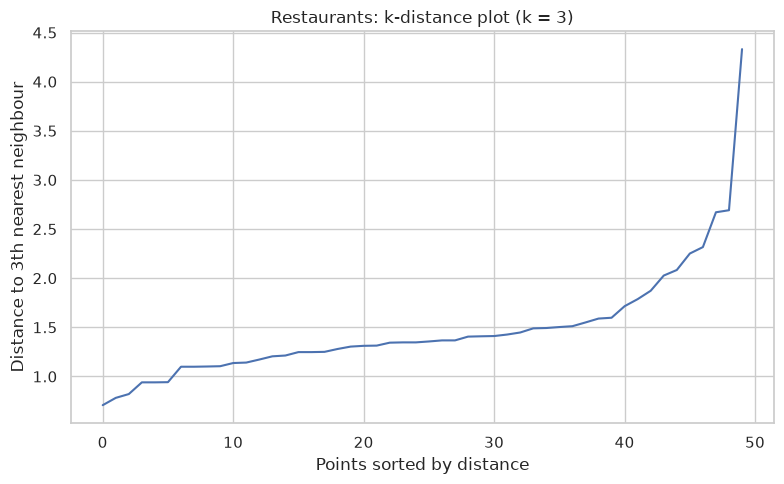


Restaurants DBSCAN grid (min_samples=3):
 eps  clusters  noise_points  noise_pct  silhouette_excl_noise
 1.0         2            41       82.0                  0.698
 1.2         4            28       56.0                  0.294
 1.4         4            12       24.0                  0.249
 1.6         1             7       14.0                    NaN
 1.8         1             7       14.0                    NaN
 2.0         1             6       12.0                    NaN
 2.2         1             4        8.0                    NaN
 2.4         1             2        4.0                    NaN
 2.6         1             2        4.0                    NaN

Selected eps = 1.4, min_samples = 3
Dense clusters found: 4
Noise / outlier points: 12 (24.0%)
-1    12
 0    14
 1    18
 2     3
 3     3
Silhouette score (excluding noise): 0.249


['/home/sharath/projects/uber-eats-intelligence/src/models/restaurant_dbscan.joblib']

In [11]:
def plot_k_distance(X_scaled, k, prefix):
    distances = np.sort(
        NearestNeighbors(n_neighbors=k).fit(X_scaled).kneighbors(X_scaled)[0][:, -1]
    )
    plt.figure(figsize=(8, 5))
    plt.plot(distances)
    plt.title(f"{prefix}: k-distance plot (k = {k})")
    plt.xlabel("Points sorted by distance")
    plt.ylabel(f"Distance to {k}th nearest neighbour")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{prefix.lower()}_kdistance.png", dpi=150, bbox_inches="tight")
    plt.show()


def tune_dbscan(X_scaled, min_samples, eps_grid, max_noise_pct):
    rows = []
    for eps in eps_grid:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_clusters = len(set(labels) - {-1})
        mask = labels != -1
        sil = (silhouette_score(X_scaled[mask], labels[mask])
               if n_clusters >= 2 else np.nan)
        rows.append({"eps": round(eps, 2), "clusters": n_clusters,
                     "noise_points": int((~mask).sum()),
                     "noise_pct": round(100 * (~mask).mean(), 1),
                     "silhouette_excl_noise": sil})
    grid = pd.DataFrame(rows)

    ok = grid[grid["noise_pct"] <= max_noise_pct]
    multi = ok[ok["clusters"] >= 2]
    if len(multi):                       # prefer several dense groups, best silhouette
        best = multi.loc[multi["silhouette_excl_noise"].idxmax()]
    elif len(ok):                        # otherwise smallest eps that keeps noise low
        best = ok.iloc[0]
    else:
        best = grid.iloc[-1]
    return grid, float(best["eps"])


def run_dbscan(X_scaled, prefix, min_samples, eps_grid, max_noise_pct):
    plot_k_distance(X_scaled, min_samples, prefix)
    grid, eps = tune_dbscan(X_scaled, min_samples, eps_grid, max_noise_pct)

    print(f"\n{prefix} DBSCAN grid (min_samples={min_samples}):")
    print(grid.round(3).to_string(index=False))

    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X_scaled)
    mask = labels != -1
    n_clusters = len(set(labels) - {-1})

    print(f"\nSelected eps = {eps}, min_samples = {min_samples}")
    print("Dense clusters found:", n_clusters)
    print("Noise / outlier points:", int((~mask).sum()),
          f"({100 * (~mask).mean():.1f}%)")
    print(pd.Series(labels).value_counts().sort_index().rename("points").to_string())

    if n_clusters >= 2:
        print("Silhouette score (excluding noise):",
              round(silhouette_score(X_scaled[mask], labels[mask]), 3))
    else:
        print("Silhouette score not defined: DBSCAN found a single dense group "
              "plus outliers.")
    return model, labels


# Customers: 5 features -> min_samples = 10 (about 2 x dimensions)
customer_dbscan, customer_features["dbscan_cluster"] = run_dbscan(
    customer_scaled, "Customers", min_samples=10,
    eps_grid=np.arange(0.8, 2.61, 0.2), max_noise_pct=10
)

# Restaurants: only 50 points -> small min_samples
restaurant_dbscan, restaurant_features["dbscan_cluster"] = run_dbscan(
    restaurant_scaled, "Restaurants", min_samples=3,
    eps_grid=np.arange(1.0, 2.61, 0.2), max_noise_pct=35
)

joblib.dump(customer_dbscan, MODELS_DIR / "customer_dbscan.joblib")
joblib.dump(restaurant_dbscan, MODELS_DIR / "restaurant_dbscan.joblib")

In [12]:
# What makes the DBSCAN outliers different from the dense core?
customer_features["is_outlier"] = (customer_features["dbscan_cluster"] == -1)
restaurant_features["is_outlier"] = (restaurant_features["dbscan_cluster"] == -1)

print("Customer outliers vs core (feature means):")
display(
    customer_features.groupby("is_outlier")[customer_feature_cols + ["total_spending"]]
    .mean().round(2).rename(index={False: "dense core", True: "outliers (noise)"})
)

print("Restaurant outliers vs dense groups (feature means):")
display(
    restaurant_features.groupby("is_outlier")[restaurant_feature_cols]
    .mean().round(2).rename(index={False: "dense groups", True: "outliers (noise)"})
)

Customer outliers vs core (feature means):


,total_orders,average_order_value,average_rating_given,weekend_share,late_night_share,total_spending
is_outlier,,,,,,
dense core,9.08,812.58,3.99,0.29,0.30,7346.19
outliers (noise),4.84,869.72,3.30,0.33,0.34,4192.60


Restaurant outliers vs dense groups (feature means):


,total_orders,revenue,average_rating,average_prep_time,cancellation_rate,average_delivery_time
is_outlier,,,,,,
dense groups,101.47,72489.88,3.93,24.92,0.09,59.83
outliers (noise),95.33,68393.35,3.98,24.17,0.10,59.05


## Part 5 – PCA visualisation
PCA compresses the scaled features into two components so the clusters can be plotted. DBSCAN noise is drawn in grey.

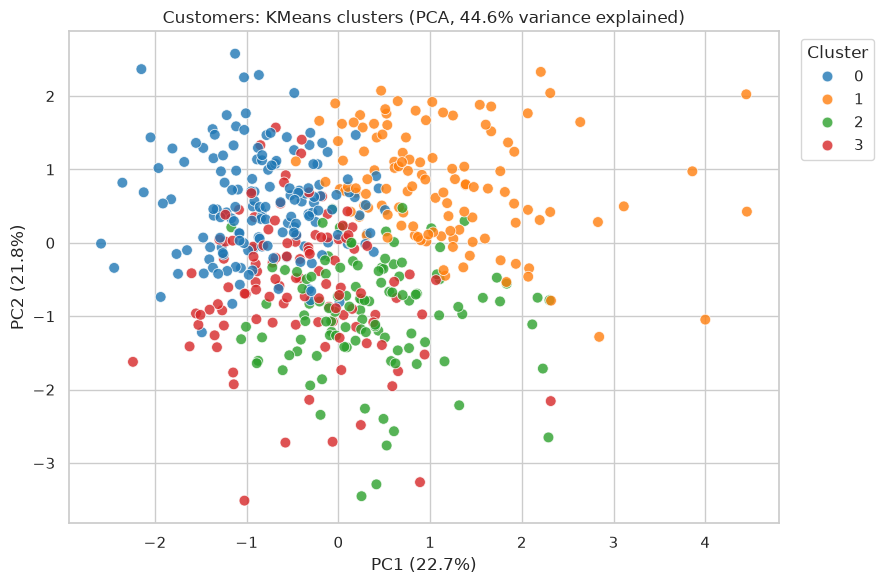

Customers KMeans: variance explained by 2 components = 44.57%


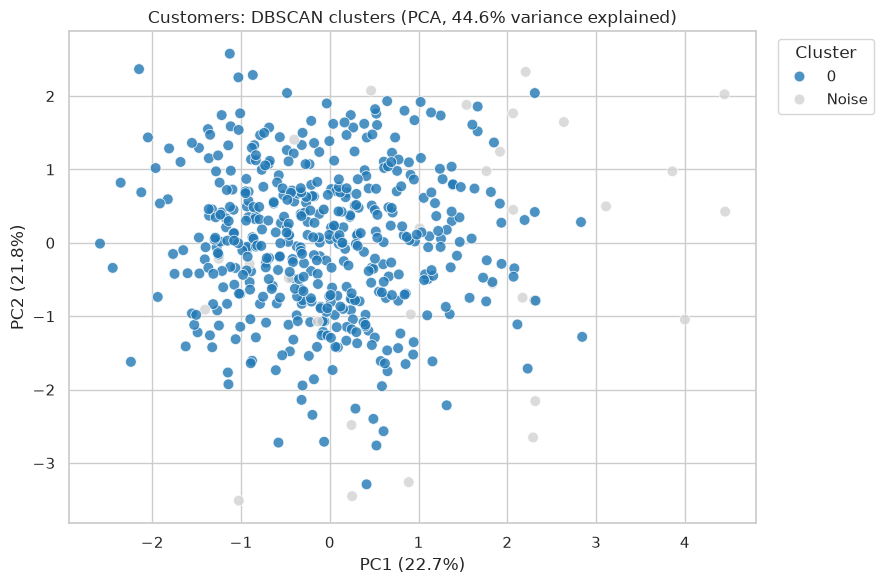

Customers DBSCAN: variance explained by 2 components = 44.57%


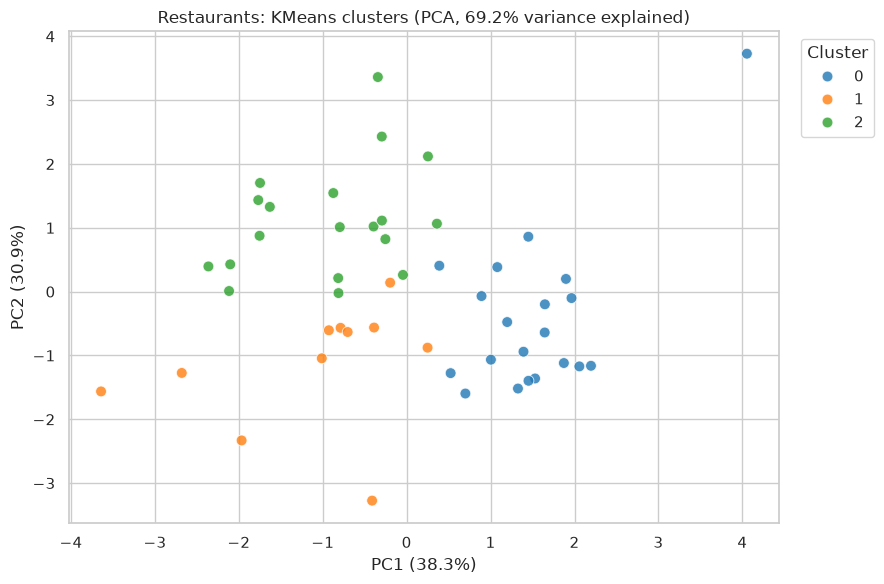

Restaurants KMeans: variance explained by 2 components = 69.20%


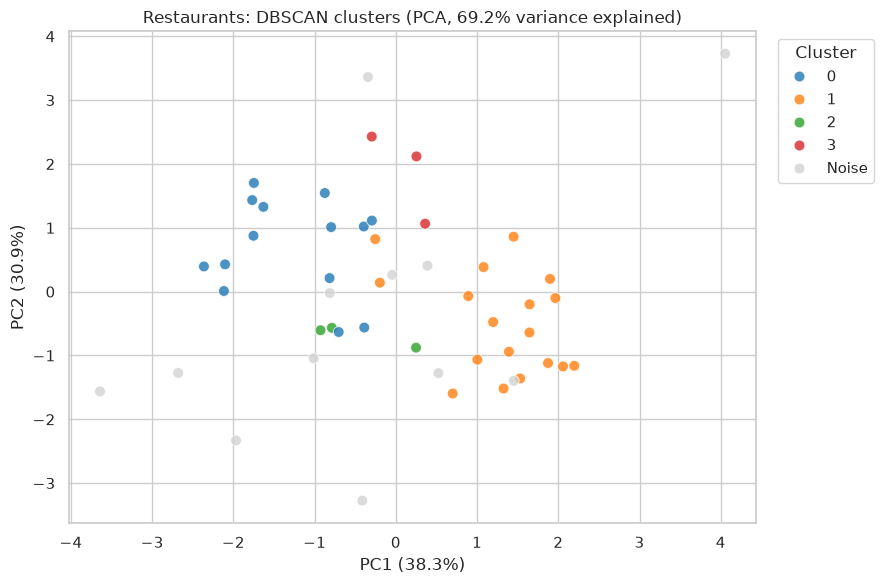

Restaurants DBSCAN: variance explained by 2 components = 69.20%

Customer PCA loadings:
                       PC1   PC2
total_orders         -0.56  0.44
average_order_value   0.62 -0.16
average_rating_given -0.48 -0.40
weekend_share         0.08  0.66
late_night_share     -0.25 -0.42

Restaurant PCA loadings:
                        PC1   PC2
total_orders           0.45  0.48
revenue                0.44  0.49
average_rating         0.01 -0.47
average_prep_time      0.54 -0.40
cancellation_rate      0.08 -0.11
average_delivery_time  0.55 -0.37


In [13]:
def plot_pca_clusters(X_scaled, labels, prefix, algorithm):
    pca = PCA(n_components=2, random_state=42)
    components = pca.fit_transform(X_scaled)

    plot_df = pd.DataFrame({
        "PC1": components[:, 0],
        "PC2": components[:, 1],
        "Cluster": np.where(labels == -1, "Noise", labels.astype(str))
    })

    cluster_order = sorted(c for c in plot_df["Cluster"].unique() if c != "Noise")
    palette = dict(zip(cluster_order, sns.color_palette("tab10", len(cluster_order))))
    palette["Noise"] = "lightgrey"

    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=plot_df, x="PC1", y="PC2", hue="Cluster",
        hue_order=cluster_order + (["Noise"] if "Noise" in plot_df["Cluster"].values else []),
        palette=palette, s=60, alpha=0.8
    )
    var = pca.explained_variance_ratio_.sum() * 100
    plt.title(f"{prefix}: {algorithm} clusters (PCA, {var:.1f}% variance explained)")
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{prefix.lower()}_{algorithm.lower()}_pca.png",
                dpi=150, bbox_inches="tight")
    plt.show()

    print(f"{prefix} {algorithm}: variance explained by 2 components = {var:.2f}%")
    return pca


customer_pca = plot_pca_clusters(
    customer_scaled, customer_features["kmeans_cluster"].to_numpy(), "Customers", "KMeans")
plot_pca_clusters(
    customer_scaled, customer_features["dbscan_cluster"].to_numpy(), "Customers", "DBSCAN")

restaurant_pca = plot_pca_clusters(
    restaurant_scaled, restaurant_features["kmeans_cluster"].to_numpy(), "Restaurants", "KMeans")
plot_pca_clusters(
    restaurant_scaled, restaurant_features["dbscan_cluster"].to_numpy(), "Restaurants", "DBSCAN")

# Which original features drive each component?
print("\nCustomer PCA loadings:")
print(pd.DataFrame(customer_pca.components_.T, index=customer_X.columns,
                   columns=["PC1", "PC2"]).round(2))
print("\nRestaurant PCA loadings:")
print(pd.DataFrame(restaurant_pca.components_.T, index=restaurant_X.columns,
                   columns=["PC1", "PC2"]).round(2))

## Cluster profiles and business names

In [14]:
# The 7 required customer features + the two share features used in the model
customer_profile_cols = [
    "total_orders", "average_order_value", "total_spending",
    "ordering_frequency", "average_rating_given",
    "weekend_orders", "late_night_orders",
    "weekend_share", "late_night_share"
]

customer_profiles = (
    customer_features.groupby("kmeans_cluster")[customer_profile_cols].mean().round(2)
)
customer_profiles.insert(0, "n_customers",
                         customer_features["kmeans_cluster"].value_counts().sort_index())

print("Customer cluster profiles:")
display(customer_profiles)

customer_profiles.to_csv(PROCESSED_DIR / "customer_cluster_profiles.csv")

Customer cluster profiles:


,n_customers,total_orders,average_order_value,total_spending,ordering_frequency,average_rating_given,weekend_orders,late_night_orders,weekend_share,late_night_share
kmeans_cluster,,,,,,,,,,
0,156,11.98,779.62,9385.05,2.31,4.08,3.47,3.38,0.29,0.28
1,119,7.60,886.95,6654.26,1.73,3.26,2.99,1.81,0.40,0.23
2,113,7.04,852.54,6043.96,1.72,4.21,0.93,1.60,0.13,0.23
3,112,7.52,754.95,5682.52,1.79,4.22,2.51,3.55,0.33,0.48


In [15]:
def name_customer_clusters(profiles):
    """Assign business names by ranking clusters on their defining traits
    (robust to cluster-id order). Always sanity-check against the profile table."""
    names = {}
    remaining = list(profiles.index)
    overall_spend = (profiles["total_spending"] * profiles["n_customers"]).sum() / profiles["n_customers"].sum()
    overall_aov = (profiles["average_order_value"] * profiles["n_customers"]).sum() / profiles["n_customers"].sum()

    # 1. Highest order volume -> Premium Frequent Diners
    c = profiles.loc[remaining, "total_orders"].idxmax()
    names[c] = "Premium Frequent Diners"
    remaining.remove(c)

    # 2. Strongest late-night habit
    if remaining:
        c = profiles.loc[remaining, "late_night_share"].idxmax()
        high_value = profiles.loc[c, "total_spending"] >= overall_spend
        names[c] = ("Late-Night High-Value Customers" if high_value
                    else "Late-Night Budget Customers")
        remaining.remove(c)

    # 3. Strongest weekend habit
    if remaining:
        c = profiles.loc[remaining, "weekend_share"].idxmax()
        big_basket = profiles.loc[c, "average_order_value"] >= overall_aov
        names[c] = ("Weekend High-Ticket Customers" if big_basket
                    else "Weekend Value Seekers")
        remaining.remove(c)

    # 4. Everyone else
    for c in remaining:
        low_weekend = profiles.loc[c, "weekend_share"] < profiles["weekend_share"].median()
        names[c] = ("Weekday Regular Customers" if low_weekend
                    else "Occasional Customers")
    return names


customer_cluster_names = name_customer_clusters(customer_profiles)
customer_features["customer_segment"] = customer_features["kmeans_cluster"].map(customer_cluster_names)

print("Customer segment names:")
for cluster_id, name in sorted(customer_cluster_names.items()):
    print(f"  Cluster {cluster_id}: {name}")

display(customer_features[["customer_id", "kmeans_cluster", "customer_segment"]].head(10))

Customer segment names:
  Cluster 0: Premium Frequent Diners
  Cluster 1: Weekend High-Ticket Customers
  Cluster 2: Weekday Regular Customers
  Cluster 3: Late-Night Budget Customers


,customer_id,kmeans_cluster,customer_segment
0,C0001,1,Weekend High-Ticket Customers
1,C0002,1,Weekend High-Ticket Customers
2,C0003,0,Premium Frequent Diners
3,C0004,2,Weekday Regular Customers
4,C0005,1,Weekend High-Ticket Customers
5,C0006,1,Weekend High-Ticket Customers
6,C0007,2,Weekday Regular Customers
7,C0008,0,Premium Frequent Diners
8,C0009,3,Late-Night Budget Customers
9,C0010,1,Weekend High-Ticket Customers


In [16]:
restaurant_profile_cols = [
    "total_orders", "revenue", "average_rating", "average_prep_time",
    "cancellation_rate", "average_delivery_time"
]

restaurant_profiles = (
    restaurant_features.groupby("kmeans_cluster")[restaurant_profile_cols].mean().round(2)
)
restaurant_profiles.insert(0, "n_restaurants",
                           restaurant_features["kmeans_cluster"].value_counts().sort_index())
restaurant_profiles["most_common_cuisine"] = (
    restaurant_features.groupby("kmeans_cluster")["cuisine"].agg(lambda s: s.mode().iloc[0])
)

print("Restaurant cluster profiles:")
display(restaurant_profiles)

restaurant_profiles.to_csv(PROCESSED_DIR / "restaurant_cluster_profiles.csv")

Restaurant cluster profiles:


,n_restaurants,total_orders,revenue,average_rating,average_prep_time,cancellation_rate,average_delivery_time,most_common_cuisine
kmeans_cluster,,,,,,,,
0,20,105.75,76314.39,4.16,33.70,0.09,68.40,Biryani
1,11,86.73,61231.52,4.16,24.27,0.07,58.70,Biryani
2,19,101.63,72394.79,3.59,15.58,0.09,50.98,Desserts


In [17]:
def name_restaurant_clusters(profiles):
    """Rank-based naming; check the result against the profile table."""
    names = {}
    remaining = list(profiles.index)
    mean_orders = (profiles["total_orders"] * profiles["n_restaurants"]).sum() / profiles["n_restaurants"].sum()

    # 1. Slowest kitchen -> high-demand, slow-preparation
    c = profiles.loc[remaining, "average_prep_time"].idxmax()
    names[c] = "High-Demand Slow-Preparation Restaurants"
    remaining.remove(c)

    # 2. Best rated of the rest
    if remaining:
        c = profiles.loc[remaining, "average_rating"].idxmax()
        popular = profiles.loc[c, "total_orders"] >= mean_orders
        names[c] = ("High-Performing Popular Restaurants" if popular
                    else "Highly Rated Niche Restaurants")
        remaining.remove(c)

    # 3. Everything else
    for c in remaining:
        names[c] = "Fast-Prep Lower-Rated Restaurants"
    return names


restaurant_cluster_names = name_restaurant_clusters(restaurant_profiles)
restaurant_features["restaurant_segment"] = restaurant_features["kmeans_cluster"].map(restaurant_cluster_names)

print("Restaurant segment names:")
for cluster_id, name in sorted(restaurant_cluster_names.items()):
    print(f"  Cluster {cluster_id}: {name}")

display(restaurant_features[["restaurant_id", "kmeans_cluster", "restaurant_segment"]].head(10))

Restaurant segment names:
  Cluster 0: High-Demand Slow-Preparation Restaurants
  Cluster 1: Highly Rated Niche Restaurants
  Cluster 2: Fast-Prep Lower-Rated Restaurants


,restaurant_id,kmeans_cluster,restaurant_segment
0,R001,0,High-Demand Slow-Preparation Restaurants
1,R002,2,Fast-Prep Lower-Rated Restaurants
2,R003,2,Fast-Prep Lower-Rated Restaurants
3,R004,0,High-Demand Slow-Preparation Restaurants
4,R005,0,High-Demand Slow-Preparation Restaurants
5,R006,0,High-Demand Slow-Preparation Restaurants
6,R007,2,Fast-Prep Lower-Rated Restaurants
7,R008,2,Fast-Prep Lower-Rated Restaurants
8,R009,0,High-Demand Slow-Preparation Restaurants
9,R010,0,High-Demand Slow-Preparation Restaurants


In [18]:
customer_features.to_csv(PROCESSED_DIR / "customer_segmentation_results.csv", index=False)
restaurant_features.to_csv(PROCESSED_DIR / "restaurant_segmentation_results.csv", index=False)

customer_k_results.to_csv(PROCESSED_DIR / "customer_kmeans_scores.csv", index=False)
restaurant_k_results.to_csv(PROCESSED_DIR / "restaurant_kmeans_scores.csv", index=False)

print("All segmentation outputs saved successfully.")

All segmentation outputs saved successfully.


## Summary of deliverables

In [19]:
summary = pd.DataFrame({
    "Entity": ["Customers", "Restaurants"],
    "Model features": [len(customer_feature_cols), len(restaurant_feature_cols)],
    "K-Means k": [CUSTOMER_K, RESTAURANT_K],
    "K-Means silhouette": [round(customer_sil, 3), round(restaurant_sil, 3)],
    "DBSCAN clusters": [len(set(customer_features["dbscan_cluster"]) - {-1}),
                        len(set(restaurant_features["dbscan_cluster"]) - {-1})],
    "DBSCAN outliers": [int((customer_features["dbscan_cluster"] == -1).sum()),
                        int((restaurant_features["dbscan_cluster"] == -1).sum())],
})
display(summary)

print("\nCustomer segments:")
display(customer_features["customer_segment"].value_counts().rename("customers").to_frame())
print("Restaurant segments:")
display(restaurant_features["restaurant_segment"].value_counts().rename("restaurants").to_frame())

,Entity,Model features,K-Means k,K-Means silhouette,DBSCAN clusters,DBSCAN outliers
0,Customers,5,4,0.157,1,31
1,Restaurants,6,3,0.260,4,12



Customer segments:


,customers
customer_segment,
Premium Frequent Diners,156
Weekend High-Ticket Customers,119
Weekday Regular Customers,113
Late-Night Budget Customers,112


Restaurant segments:


,restaurants
restaurant_segment,
High-Demand Slow-Preparation Restaurants,20
Fast-Prep Lower-Rated Restaurants,19
Highly Rated Niche Restaurants,11
